# Интеллектуальные методы обработки видео

# Ноутбук разделен на два задания:
   * ### [Эвристический SCD](#first)
   * ### [SCD с ML](#second)
   
Сроки выполнения для каждого задания — одна неделя. Оцениваются задания независимо.

## Задание 1. Scene Change Detector
<a id='first'></a>

### Обязательно к прочтению

**Внимание!**

Opencv содержит очень много высокоуровневых функций обработки изображений (например, некоторые алгоритмы компенсации движения, отслеживания объектов, распознавания образов). Использование данной библиотеки в данном задании ограничивается:
* считыванием входного видео
* преобразованием его кадров в другие цветовые пространства
* использованием свёрток Собеля

Использовать библиотеку numpy можно без ограничений.

Если вы хотите использовать функции обработки изображений и видео из другой библиотеки, то оговорите использование этой функции в чате курса.

### Описание входных данных

# Выборка для тренировки лежит https://titan.gml-team.ru:5003/sharing/yX8enupJV

Данные о каждом видео лежат в файле *train_dataset\info.json*. Это список из словарей, каждый словарь содержит информацию о расположении видео, о расположении ответов на смены сцен и содержит длину видео

In [1]:
import numpy as np
import cv2 # Для установки opencv воспользуйтесь командой в терминале conda install -c conda-forge opencv
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
import os

%matplotlib inline

c:\Users\0808\Code\Zadanie1IIT\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import json

def load_json_from_file(filename):
    with open(filename, "r") as f:
        return json.load(f, strict=False)  # ← есть отступ (4 пробела или Tab)

def dump_json_to_file(obj, filename, **kwargs):
    with open(filename, "w") as f:
        json.dump(obj, f, **kwargs)  # ← тоже с отступом

In [6]:
video_dataset = load_json_from_file('train_dataset\info.json')
video_dataset

[{'source': 'video/03.mp4', 'scene_change': 'gt/03.json', 'len': 3250},
 {'source': 'video/04.mp4', 'scene_change': 'gt/04.json', 'len': 3392},
 {'source': 'video/05.mp4', 'scene_change': 'gt/05.json', 'len': 5662},
 {'source': 'video/07.mp4', 'scene_change': 'gt/07.json', 'len': 3321},
 {'source': 'video/08.mp4', 'scene_change': 'gt/08.json', 'len': 3396},
 {'source': 'video/10.mp4', 'scene_change': 'gt/10.json', 'len': 6096},
 {'source': 'video/14.mp4', 'scene_change': 'gt/14.json', 'len': 2326},
 {'source': 'video/17.mp4', 'scene_change': 'gt/17.json', 'len': 2905},
 {'source': 'video/21.mp4', 'scene_change': 'gt/21.json', 'len': 4898},
 {'source': 'video/22.mp4', 'scene_change': 'gt/22.json', 'len': 7749}]

### Загрузка видео ###

Загрузка видео осуществляется при помощи cv2.VideoCapture. Этот код изменять и дописывать не нужно.

In [3]:
def read_video(video_path):
    cap = cv2.VideoCapture(video_path)
    frames = []
    while(cap.isOpened()):
        ret, frame = cap.read()
        if ret==False:
            break
        yield frame
    cap.release()

In [5]:
frames = read_video(os.path.join('train_dataset', 'video', '03.mp4'))

Что такое frames? Это итератор на кадры видео. Чтобы пройтись по всем кадрам последовательности, воспользуйтесь следующей конструкцией:
*Аккуратно, по одной переменной frames можно пройти только один раз!*

In [6]:
for frame in tqdm(frames):
    pass
for frame in tqdm(frames): # Второй раз уже не будет итерации
    pass

3250it [00:07, 432.96it/s]
0it [00:00, ?it/s]


### Пишем свой простой детектор смен сцен

На данном этапе предлагается написать простой Scene Change Detector (SCD) на основе выделения характеристик кадров, подсчёта разницы между кадрами на основе данных характеристик, а также подобрать наиболее оптимальный порог для этих признаков и совместить эти признаки.
Сменой сцен в данной задаче являются только обычные мгновенные смены сцен, без дополнительных эффектов.

В качестве примера приведён простой детектор смен, который считает межкадровую разницу между кадрами.

*Важное замечание. Здесь и далее результатом алгоритма детектора сцен являются **индексы кадров начал сцен**, при этом кадры **нумеруются с 0**. Нулевой кадр в качестве ответа указывать не нужно*

In [14]:
<img src="Hard_cut[1].jpg" >

SyntaxError: invalid syntax (644178054.py, line 1)

In [15]:
def baseline_scene_change_detector(frames, threshold=2000, with_vis=False):
    """
    Baseline SCD

    Arguments:
    frames -- iterator on video frames
    threshold -- parameter of your algorithm (optional)
    with_vis -- saving neighboring frames at a scene change (optional)

    Returns:
    scene_changes -- list of scene changes (idx of frames)
    vis -- list of neighboring frames at a scene change (for visualization)
    metric_values -- list of metric values (for visualization)
    """
    
    def pixel_metric(frame, prev_frame):
        # Базовое расстояние между кадрами - среднеквадратическая ошибка между ними
        return np.mean((frame.astype(np.int32) - prev_frame) ** 2)

    scene_changes = []
    vis = []
    metric_values = []
    prev_frame = None
    for idx, frame in tqdm(enumerate(frames), leave=False):
        # frame - это кадр
        # idx - это номер кадра
        if prev_frame is not None:
            # Находим расстояние между соседними кадрами
            metric_value = pixel_metric(frame, prev_frame)
            if metric_value > threshold:
                scene_changes.append(idx)
                if with_vis:
                    # Кадры в памяти занимают много места, поэтому сохраним лишь первые 100 срабатываний
                    if len(vis) < 100:
                        vis.append([prev_frame, frame])
            metric_values.append(metric_value)
        else:
            metric_values.append(0)
        prev_frame = frame
    return scene_changes, vis, metric_values

In [8]:
frames = read_video(os.path.join(r'C:\Users\0808\Downloads\train_dataset\train_dataset', 'video', '03.mp4'))
cuts_base = load_json_from_file(os.path.join(r'C:\Users\0808\Downloads\train_dataset\train_dataset', 'gt', '03.json'))['cut']
scene_changes_base, vis_base, metric_values_base = baseline_scene_change_detector(frames, with_vis=True)

Посмотрим визуально, насколько сильно алгоритм ошибается, а также на значения метрики

In [4]:
def visualize_metric_error(frame, prev_frame, value):
    fig = plt.figure(figsize=(16,4))
    plt.suptitle('Значение метрики на текущем кадре: {:.4f}'.format(value), fontsize=24)
    ax = fig.add_subplot(1, 2, 1)
    ax.imshow(prev_frame[:,:,::-1])
    ax.set_title("Предыдущий кадр", fontsize=18)
    ax.set_xticks([])
    ax.set_yticks([])
    ax = fig.add_subplot(1, 2, 2)
    ax.imshow(frame[:,:,::-1])
    ax.set_title("Текущий кадр", fontsize=18)
    ax.set_xticks([])
    ax.set_yticks([])
    plt.subplots_adjust(top=0.80)

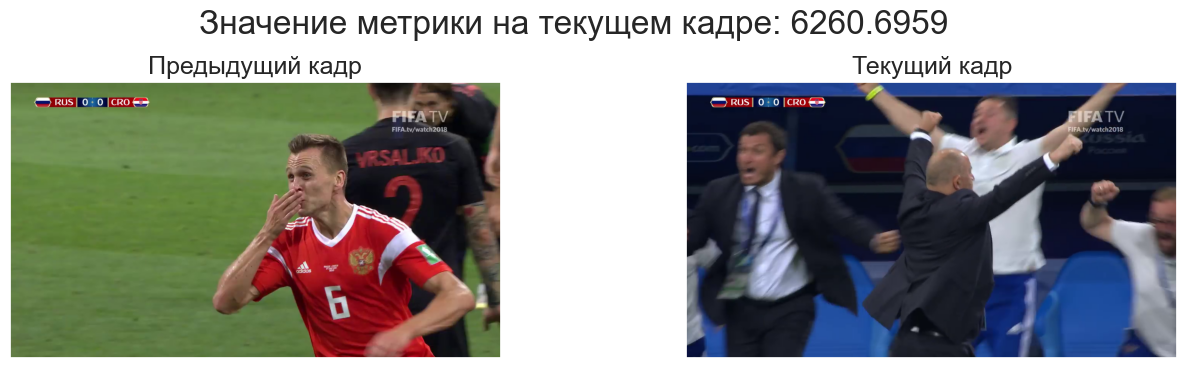

In [17]:
idx = 1
visualize_metric_error(vis_base[idx][0], vis_base[idx][1], metric_values_base[scene_changes_base[idx]])
# смена сцен

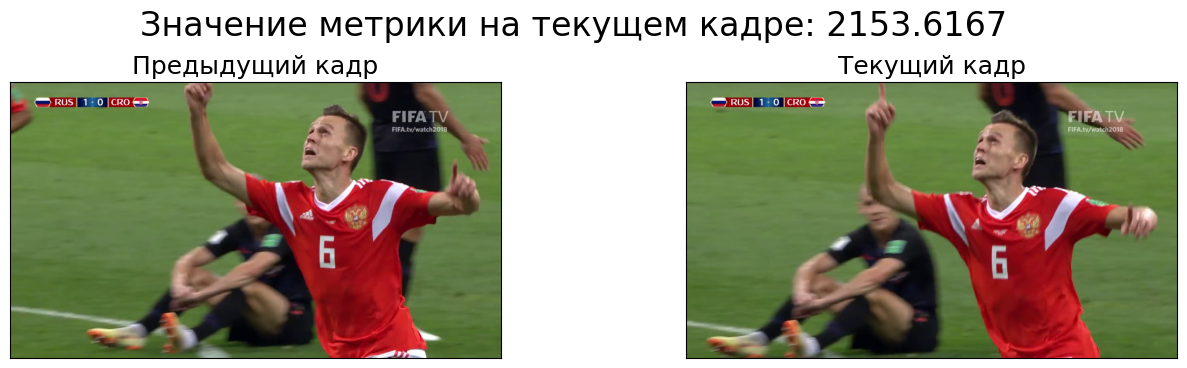

In [11]:
idx = 7
visualize_metric_error(vis_base[idx][0], vis_base[idx][1], metric_values_base[scene_changes_base[idx]])
# ошибается, это не смена сцен

In [10]:
def visualize_metric_values(metric_values, threshold, cuts = None):
    sns.set()
    plt.figure(figsize=(16, 8))
    plt.plot(metric_values, label='Значение метрики на кадрах')
    plt.xlabel('Номер кадра')
    plt.ylabel('Значение метрики')
    plt.hlines(y=threshold, xmin=0, xmax=len(metric_values), linewidth=2, color='r', label='Пороговое значение')
    
    if cuts is not None:
        for cut in cuts:
            plt.axvline(x=cut, color='k', linestyle=':', linewidth=0.5, label='Смена сцены')

    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    plt.legend(by_label.values(), by_label.keys())
    plt.show()

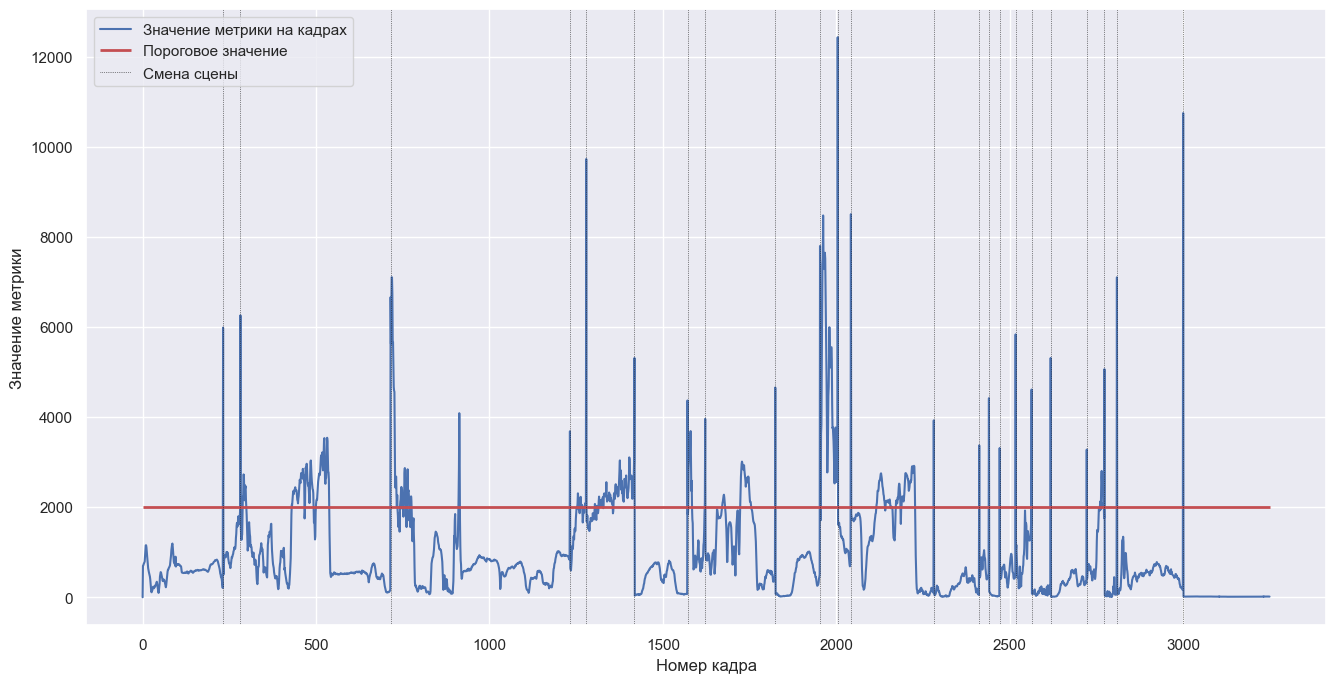

In [13]:
visualize_metric_values(metric_values_base, 2000, cuts_base)

**Как видим, очень плохо подобран порог, да и сам признак, похоже, сильно зашумлён. Попробуйте что-то своё!**

### Ваше решение

* В качестве решения вы должны прикрепить функцию ниже. Все пороги должны быть указаны внутри функции.  
Т.е. должен быть возможен вызов:  
`scene_changes, vis, metric_values = scene_change_detector(frames)`  
* Строку (# GRADED CELL: [function name]) менять **нельзя**. Она будет использоваться при проверке вашего решения.
* Ячейка должна содержать только **одну** функцию.

In [5]:
# GRADED CELL: scene_change_detector

def scene_change_detector(frames, threshold=0.43, with_vis=False):
    scene_changes = []
    vis = []
    metric_values = []
    
    ### START CODE HERE ###
    prev_hist = None
    prev_blockvhist = None
    prev_frame = None
    s_means = []
    ###  END CODE HERE  ###
    
   
    
    for idx, frame in enumerate(frames):
        
        ### START CODE HERE ###
        small = cv2.resize(frame, (0, 0), fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
        hsv = cv2.cvtColor(small, cv2.COLOR_BGR2HSV)

        s_mean = float(hsv[:, :, 1].mean())
        s_means.append(s_mean)

        hist = cv2.calcHist([hsv], [0, 1], None, [50, 60], [0, 180, 0, 256])
        cv2.normalize(hist, hist, alpha=1, beta=0, norm_type=cv2.NORM_L1)

        gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)

        gh, gw = gray.shape
        grid = 4
        bh, bw = gh // grid, gw // grid

        blockvhist = []
        for r in range(grid):
            for c in range(grid):
                block = gray[r*bh:(r+1)*bh, c*bw:(c+1)*bw]
                h = cv2.calcHist([block], [0], None, [32], [0, 256])
                cv2.normalize(h, h, alpha=1, beta=0, norm_type=cv2.NORM_L1)
                blockvhist.append(h)
        ### END CODE HERE ###

        ### START CODE HERE ###
        if prev_hist is None:
            diff = 0.0
        else:
            d_hs = float(cv2.compareHist(prev_hist, hist, cv2.HISTCMP_BHATTACHARYYA))

            d_blockv = 0.0
            for h_prev, h_cur in zip(prev_blockvhist, blockvhist):
                d_blockv += float(cv2.compareHist(h_prev, h_cur, cv2.HISTCMP_BHATTACHARYYA))
            d_blockv /= len(blockvhist)

            
            alpha = min(1.0, max(0.0, (s_mean - 5) / 40))  
            diff = alpha * d_hs + (1 - alpha) * d_blockv

        metric_values.append(diff)

        prev_hist = hist
        prev_blockvhist = blockvhist
        prev_frame = frame
        ### END CODE HERE ###

    if threshold is None:
        return scene_changes, vis, metric_values

    last_cut = -10**9
    min_dist = 10

    thr = threshold

    for idx in range(1, len(metric_values)-1):
        if metric_values[idx] > thr and \
           metric_values[idx] > metric_values[idx-1] and \
           metric_values[idx] >= metric_values[idx+1] and \
           idx - last_cut > min_dist:

            scene_changes.append(idx)
            last_cut = idx

            if with_vis and len(vis) < 100:
                vis.append([frames[idx-1], frames[idx]])
 
    return scene_changes, vis, metric_values

In [19]:
frames = read_video(os.path.join(r'C:\Users\0808\Downloads\train_dataset\train_dataset', 'video', '03.mp4'))
cuts = load_json_from_file(os.path.join(r'C:\Users\0808\Downloads\train_dataset\train_dataset', 'gt', '03.json'))['cut']
scene_changes, vis, metric_values = scene_change_detector(frames,threshold = 0.43, with_vis=True)

TypeError: 'generator' object is not subscriptable

In [154]:
print("diff min/max:", float(np.min(metric_values)), float(np.max(metric_values)))
print("top23 diffs:", np.sort(metric_values)[-23:])

NameError: name 'metric_values' is not defined

#### Обратите внимание на скорость работы алгоритма! ####
Если вычислять признаки без циклов по пикселям, а пользоваться методами из numpy, то скорость будет не медленнее 7-8 кадров в секунду.
Например, вы можете использовать функцию `np.histogram` или `cv2.calcHist` для подсчёта гистограмм, а `cv2.Sobel` для применения оператора Собеля к кадру.

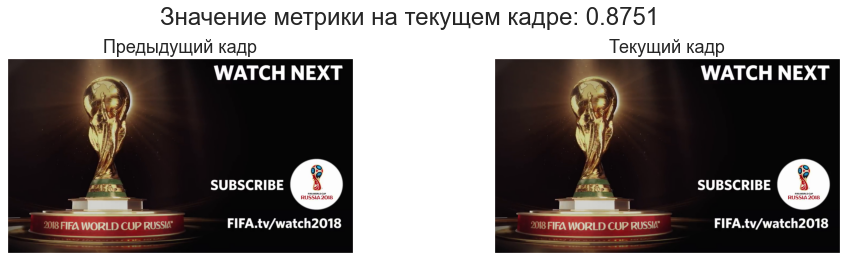

In [269]:
#Посмотрим на найденные смены сцен
idx = 22
visualize_metric_error(vis[idx][0], vis[idx][1], metric_values[scene_changes[idx]])

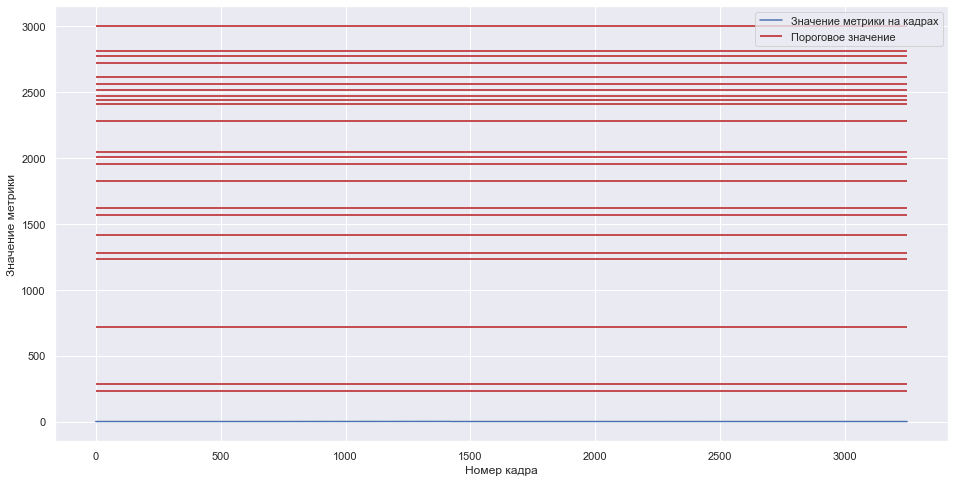

In [270]:
#Посмотрим на значения метрики
visualize_metric_values(metric_values, cuts)

### Подсчёт метрики F1-Score

Чтобы оценивать алгоритм и научиться сравнивать несколько алгоритмов, нужна метрика качества. В данной задаче для оценки качества алгоритма используется F1-Score. Преимущества использования этой метрики к текущей постановке задачи смены сцен были рассказаны на лекции, напишем только формулы:
$$precision = \frac{tp}{tp+fp}$$
$$recall = \frac{tp}{tp+fn}$$
$$F = 2 * \frac{precision * recall}{precision+recall}$$

На всякий случай опишем как именно происходит подсчёт метрики для видео

1) Сначала из выборки удаляются все кадры, которые по разметке либо являются сложными переходами между сценами, либо помечены как сложные для анализа и разметки (например, титры/обилие компьютерной графики и т.п)


2) Затем для оставшихся кадров уже подсчитывается F1_Score

In [6]:
#Эти пять клеток кода править не нужно
def calculate_matrix(true_scd, predicted_scd, scene_len, not_to_use_frames=set()):
    predicted_scd = set(predicted_scd)
    tp, fp, tn, fn = 0, 0, 0, 0
    scene_len = scene_len
    for scd in predicted_scd:
        if scd in true_scd:
            tp += 1
        elif scd not in not_to_use_frames:
            fp += 1
    for scd in true_scd:
        if scd not in predicted_scd:
            fn += 1
    tn = scene_len - len(not_to_use_frames) - tp - fp - fn
    return tp, fp, tn, fn

In [7]:
def calculate_precision(tp, fp, tn, fn):
    return tp / max(1, (tp + fp))

In [8]:
def calculate_recall(tp, fp, tn, fn):
    return tp / max(1, (tp + fn))

In [9]:
def f1_score(true_scd, predicted_scd, scene_len, not_to_use_frames=set()):
    tp, fp, tn, fn = calculate_matrix(true_scd, predicted_scd, scene_len, not_to_use_frames)
    precision_score = calculate_precision(tp, fp, tn, fn)
    recall_score = calculate_recall(tp, fp, tn, fn)
    if precision_score + recall_score == 0:
        return 0
    else:
        return 2 * precision_score * recall_score / (precision_score + recall_score)

In [10]:
def f1_score_matrix(tp, fp, tn, fn):
    precision_score = calculate_precision(tp, fp, tn, fn)
    recall_score = calculate_recall(tp, fp, tn, fn)
    if precision_score + recall_score == 0:
        return 0
    else:
        return 2 * precision_score * recall_score / (precision_score + recall_score)

### Тестируем разработанный метод сразу на нескольких видео 

In [11]:
def run_scene_change_detector_all_video(scene_change_detector, dataset_path):
    video_dataset = load_json_from_file(os.path.join(dataset_path, r'info.json'))
    param_log = {
        '_mean_f1_score': []
    }
    for video_info in tqdm(video_dataset, leave=False):
        # Загружаем видео, его длину и смены сцен
        frames = read_video(os.path.join(dataset_path, video_info['source']))
        video_len = video_info['len']
        true_scene_changes = load_json_from_file(os.path.join(dataset_path, video_info['scene_change']))
        
        # Составляем список сцен, которые не будут тестироваться
        not_use_frames = set()
        for type_scene_change in ['trash', 'fade', 'dissolve']:
            for bad_scene_range in true_scene_changes.get(type_scene_change, []):
                not_use_frames.update(list(range(bad_scene_range[0], bad_scene_range[1] + 1)))
        
        predicted_scene_changes, _, _ = scene_change_detector(frames)
        
        param_log['f1_score_{}'.format(video_info['source'])] = f1_score(
            true_scene_changes['cut'],
            predicted_scene_changes,
            video_len,
            not_use_frames
        )
        video_tp, video_fp, video_tn, video_fn = calculate_matrix(
            true_scene_changes['cut'],
            predicted_scene_changes,
            video_len,
            not_use_frames
        )
        
        param_log['tp_{}'.format(video_info['source'])] = video_tp
        param_log['fp_{}'.format(video_info['source'])] = video_fp
        param_log['tn_{}'.format(video_info['source'])] = video_tn
        param_log['fn_{}'.format(video_info['source'])] = video_fn 
        param_log['_mean_f1_score'].append(param_log['f1_score_{}'.format(video_info['source'])])
    param_log['_mean_f1_score'] = np.mean(param_log['_mean_f1_score'])
    return param_log

In [12]:
video_dataset = r'train_dataset'

Данная функция поможет вам посмотреть, на каких видео и на сколько ошибается ваш метод. Прогнать метод на отдельном видео и детально посмотреть кадры вы могли выше.

Кроме того, с помощью этой функции вы можете подобрать оптимальные параметры для метода.

In [ ]:
#Протестируем базовый метод
run_scene_change_detector_all_video(baseline_scene_change_detector, video_dataset)

In [19]:
#Протестируем разработанный вами метод
run_scene_change_detector_all_video(scene_change_detector, video_dataset)

  0%|          | 0/10 [00:00<?, ?it/s]

{'_mean_f1_score': np.float64(0.8663922975691388),
 'f1_score_video/03.mp4': 1.0,
 'tp_video/03.mp4': 23,
 'fp_video/03.mp4': 0,
 'tn_video/03.mp4': 3172,
 'fn_video/03.mp4': 0,
 'f1_score_video/04.mp4': 0.9473684210526316,
 'tp_video/04.mp4': 27,
 'fp_video/04.mp4': 0,
 'tn_video/04.mp4': 3358,
 'fn_video/04.mp4': 3,
 'f1_score_video/05.mp4': 0.9444444444444444,
 'tp_video/05.mp4': 17,
 'fp_video/05.mp4': 1,
 'tn_video/05.mp4': 5255,
 'fn_video/05.mp4': 1,
 'f1_score_video/07.mp4': 0.9852216748768472,
 'tp_video/07.mp4': 100,
 'fp_video/07.mp4': 1,
 'tn_video/07.mp4': 3218,
 'fn_video/07.mp4': 2,
 'f1_score_video/08.mp4': 0.6470588235294118,
 'tp_video/08.mp4': 11,
 'fp_video/08.mp4': 0,
 'tn_video/08.mp4': 2587,
 'fn_video/08.mp4': 12,
 'f1_score_video/10.mp4': 0.6865671641791046,
 'tp_video/10.mp4': 23,
 'fp_video/10.mp4': 2,
 'tn_video/10.mp4': 2696,
 'fn_video/10.mp4': 19,
 'f1_score_video/14.mp4': 0.975609756097561,
 'tp_video/14.mp4': 40,
 'fp_video/14.mp4': 2,
 'tn_video/14.mp4

Когда вы смотрите на результат, обращайте внимание на **_mean_f1_score**  
Именно по этой метрике будет производится финальное оценивание.

## Бонусное задание: распознавание смен сцен типа "наложения"

На практике кроме катов часто встречаются смены сцен, где происходит "наложение" одной сцены на другую:

<img src="Dissolve.jpg">

### Ваше решение 

* В качестве решения вы должны прикрепить функцию ниже. Все пороги должны быть указаны внутри функции.  
Т.е. должен быть возможен вызов:  
`scene_changes, vis, metric_values = scene_change_detector_dissolve(frames)`  
* Строку (# GRADED CELL: [function name]) менять **нельзя**. Она будет использоваться при проверке вашего решения.
* Ячейка должна содержать только **одну** функцию.

In [33]:
# GRADED CELL: scene_change_detector_dissolve

def scene_change_detector_dissolve(frames, threshold=None, with_vis=False):
    scene_changes = []
    vis = []
    metric_values = []
    
    prev_hist = None
    change_start = None
    min_length = 4
    last_pred = -10**9
    min_dist = 20

    if threshold is None:
        threshold = 0.13
    
    for idx, frame in tqdm(enumerate(frames), leave=False):
        small = cv2.resize(frame, (0, 0), fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
        hsv = cv2.cvtColor(small, cv2.COLOR_BGR2HSV)

        hist = cv2.calcHist([hsv], [0, 1], None, [50, 60], [0, 180, 0, 256])
        cv2.normalize(hist, hist, alpha=1, beta=0, norm_type=cv2.NORM_L1)

        if prev_hist is None:
            diff = 0.0
        else:
            diff = float(cv2.compareHist(prev_hist, hist, cv2.HISTCMP_BHATTACHARYYA))

        metric_values.append(diff)
        prev_hist = hist

        left = max(0, idx - 5)
        local_segment = metric_values[left:idx]
        local_mean = np.mean(local_segment) if len(local_segment) > 0 else 0.0

        if diff > threshold and diff > local_mean * 1.2:
            if change_start is None:
                change_start = idx - 1
        else:
            if change_start is not None:
                change_end = idx - 1
                run_len = change_end - change_start + 1

                if run_len >= min_length:
                    segment = metric_values[max(0, change_start):change_end + 1]
                    seg_mean = np.mean(segment)
                    seg_max = np.max(segment)

                    if seg_mean > threshold * 1.05 and seg_max > threshold * 1.3:
                        pred = (change_start + change_end) // 2
                        if pred - last_pred > min_dist:
                            scene_changes.append(pred)
                            last_pred = pred
                            if with_vis and len(vis) < 100:
                                vis.append([pred - 1, pred + 1])

                change_start = None

    if change_start is not None:
        change_end = idx
        run_len = change_end - change_start + 1

        if run_len >= min_length:
            segment = metric_values[max(0, change_start):change_end + 1]
            seg_mean = np.mean(segment)
            seg_max = np.max(segment)

            if seg_mean > threshold * 1.05 and seg_max > threshold * 1.3:
                pred = (change_start + change_end) // 2
                if pred - last_pred > min_dist:
                    scene_changes.append(pred)
                    if with_vis and len(vis) < 100:
                        vis.append([pred - 1, pred + 1])

    return scene_changes, vis, metric_values

В качестве метрики качества используется видоизменённый f1-score:

Так как смена сцен не происходит за один кадр, попаданием считается попадание ответа смены сцен в отрезок, где происходит наложение.  
**Обратите внимание**, что несколько раз указывать одну смену сцен не нужно.

Попадание вне отрезков смен сцен путём наложения считается как false positive, не попадание в указанный отрезок - как false negative

In [34]:
#Эти три клетки кода править не нужно
def calculate_matrix_dissolve(true_scd, predicted_scd, scene_len):
    predicted_scd = set(predicted_scd)
    tp, fp, tn, fn = 0, 0, 0, 0
    scene_len = scene_len
    checked_dissolve_segments = set()
    total_scene_dissolve_len = np.sum([dissolve_segment[1] - dissolve_segment[0] + 1 for dissolve_segment in true_scd])
    for scd in predicted_scd:
        for dissolve_segment in true_scd:
            if scd in range(dissolve_segment[0], dissolve_segment[1] + 1):
                if tuple(dissolve_segment) not in checked_dissolve_segments:
                    tp += 1
                    checked_dissolve_segments.add(tuple(dissolve_segment))
                break
        else:
            fp += 1
    fn = len(true_scd) - len(checked_dissolve_segments)
    tn = scene_len - total_scene_dissolve_len + len(true_scd) - tp - fp - fn
    return tp, fp, tn, fn

In [14]:
def f1_score_dissolve(true_scd, predicted_scd, scene_len):
    tp, fp, tn, fn = calculate_matrix_dissolve(true_scd, predicted_scd, scene_len)
    precision_score = calculate_precision(tp, fp, tn, fn)
    recall_score = calculate_recall(tp, fp, tn, fn)
    if precision_score + recall_score == 0:
        return 0
    else:
        return 2 * precision_score * recall_score / (precision_score + recall_score)

In [15]:
def run_scene_change_detector_all_video_dissolve(scene_change_detector, dataset_path):
    video_dataset = load_json_from_file(os.path.join(dataset_path, r'C:\Users\0808\info.json'))
    param_log = {
        '_mean_f1_score': []
    }
    for video_info in tqdm(video_dataset, leave=False):
        frames = read_video(os.path.join(dataset_path, video_info['source']))
        video_len = video_info['len']
        true_scene_changes = load_json_from_file(os.path.join(dataset_path, video_info['scene_change']))
        
        predicted_scene_changes, _, _ = scene_change_detector(frames)
        param_log['f1_score_{}'.format(video_info['source'])] = f1_score_dissolve(
            true_scene_changes.get('dissolve', []),
            predicted_scene_changes,
            video_len
        )
        video_tp, video_fp, video_tn, video_fn = calculate_matrix_dissolve(
            true_scene_changes.get('dissolve', []),
            predicted_scene_changes,
            video_len
        )
        param_log['tp_{}'.format(video_info['source'])] = video_tp
        param_log['fp_{}'.format(video_info['source'])] = video_fp
        param_log['tn_{}'.format(video_info['source'])] = video_tn
        param_log['fn_{}'.format(video_info['source'])] = video_fn
        param_log['_mean_f1_score'].append(param_log['f1_score_{}'.format(video_info['source'])])
    param_log['_mean_f1_score'] = np.mean(param_log['_mean_f1_score'])
    return param_log

In [16]:
video_dataset_path = r'train_dataset'

In [159]:
#Протестируем разработанный вами метод
import pandas as pd

run_scene_change_detector_all_video_dissolve(scene_change_detector_dissolve, video_dataset_path)

{'_mean_f1_score': np.float64(0.27785714285714286),
 'f1_score_video/03.mp4': 0.75,
 'tp_video/03.mp4': 6,
 'fp_video/03.mp4': 2,
 'tn_video/03.mp4': np.int64(3193),
 'fn_video/03.mp4': 2,
 'f1_score_video/04.mp4': 1.0,
 'tp_video/04.mp4': 1,
 'fp_video/04.mp4': 0,
 'tn_video/04.mp4': np.int64(3388),
 'fn_video/04.mp4': 0,
 'f1_score_video/05.mp4': 0.6,
 'tp_video/05.mp4': 3,
 'fp_video/05.mp4': 2,
 'tn_video/05.mp4': np.int64(5546),
 'fn_video/05.mp4': 2,
 'f1_score_video/07.mp4': 0,
 'tp_video/07.mp4': 0,
 'fp_video/07.mp4': 10,
 'tn_video/07.mp4': np.float64(3311.0),
 'fn_video/07.mp4': 0,
 'f1_score_video/08.mp4': 0,
 'tp_video/08.mp4': 0,
 'fp_video/08.mp4': 0,
 'tn_video/08.mp4': np.int64(3336),
 'fn_video/08.mp4': 1,
 'f1_score_video/10.mp4': 0,
 'tp_video/10.mp4': 0,
 'fp_video/10.mp4': 6,
 'tn_video/10.mp4': np.float64(6090.0),
 'fn_video/10.mp4': 0,
 'f1_score_video/14.mp4': 0.42857142857142855,
 'tp_video/14.mp4': 3,
 'fp_video/14.mp4': 8,
 'tn_video/14.mp4': np.int64(2278),

### Немного об оценивании задания

Оценивание задания будет производиться по следующей схеме:  

Пусть на скрытой выборке по F-метрике вы получили X, лучшее решение получило Y.

1. Базовая часть оценивется как $$20 * \left(\frac{\max(0, X_{base} - 0.5)}{Y_{base} - 0.5}\right)^2 + Bonus_{base}$$ Бонусные баллы $Bonus$ можно получить за оригинальные идеи в задаче или в её реализации
2. Дополнительное задание оценивается как $$5 * \frac{\max(0, X_{add} - 0.1)}{Y_{add} - 0.1} + Bonus_{add}$$Процесс получения бонусных баллов аналогичен получению бонусных баллов в базовой части

### Ваши ощущения ##

*До дедлайна пару часов и вы никак не можете улучшить текущее решение? Или наоборот, вы всё сделали очень быстро? Опишите кратко ваши ощущения от задания - сколько времени вы потратили на задание, сколько вы потратили на изучение питона и установку необходимых библиотек, как быстро вы придумывали новые идеи и как они давали прирост по метрике и в целом насколько это задание вам понравилось и что хотели бы изменить/добавить.*

<a id='second'></a>

## Задание 2. Scene change detector. Машинное обучение

**Внимание!**

В этом задании можно использовать все, что разрешалось в Задании №1, а также библиотеки:
* pandas
* sklearn

Большинство функций, использующихся в этом задании, реализованы выше.

### Бейзлайн

In [17]:
from sklearn.svm import SVC
import pandas as pd
import pickle

Обучим простой SVM классификатор над метрикой попиксельной разницы кадров на нескольких видео. Воспользуемся функцией из первого задания

In [46]:
def get_train_data(train_videos):
    X_train, y_train = np.array([]), np.array([])
    for video in train_videos:
        frames = read_video(os.path.join('train_dataset', 'video', f'{video}.mp4'))
        # baseline функция попиксельного сравнения кадров из прошлого задания
        # нам нужны не сами смены сцен, а только значения метрик
        _, _, metric_values = baseline_scene_change_detector(frames) 
        
        cuts = load_json_from_file(os.path.join('train_dataset', 'gt', f'{video}.json'))['cut']
        video_scenes = np.array([0 for i in range(len(metric_values))])
        video_scenes[cuts] += 1
        
        # добавляем в разметку текущее видео
        X_train = np.hstack((X_train, metric_values))
        y_train = np.hstack((y_train, video_scenes))
        
    return X_train, y_train 

In [47]:
train_videos = ['04', '05']

X_train, y_train = get_train_data(train_videos)

In [48]:
# создание модели
# подберите лучшие параметры для данной задачи
params = {"kernel": "rbf", "C": 1}
model = SVC(**params)
model.fit(X_train.reshape(-1, 1), y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


 Сохраним модель в файле *model.pkl*

In [49]:
pickle.dump(model, open("model.pkl", "wb"))

Посмотрим как модель работает на тестовых видео

Обратите внимание на то, что внутри функции модель загружается из памяти из файла *model.pkl*

In [50]:
def baseline_scene_change_detection_ml(frames):
    # подготавливаем данные для видео
    _, _, metric_values = baseline_scene_change_detector(frames) 
    X_test = np.array(metric_values).reshape(-1, 1)
    
    # загружаем модель и делаем предсказания
    model = pickle.load(open("model.pkl", 'rb')) 
    predict_cuts = model.predict(X_test)
    
    return np.where(predict_cuts > 0)[0], [], metric_values

In [18]:
def run_scene_change_detector_ml_one_video(scene_change_detector, dataset_path, video_num):
    video_info = load_json_from_file(os.path.join(dataset_path, 'info.json'))[video_num]
    
    # Загружаем видео, его длину и смены сцен
    frames = read_video(os.path.join(dataset_path, video_info['source']))
    video_len = video_info['len']
    true_scene_changes = load_json_from_file(os.path.join(dataset_path, video_info['scene_change']))

    # Составляем список сцен, которые не будут тестироваться
    not_use_frames = set()
    for type_scene_change in ['trash', 'fade', 'dissolve']:
        for bad_scene_range in true_scene_changes.get(type_scene_change, []):
            not_use_frames.update(list(range(bad_scene_range[0], bad_scene_range[1] + 1)))

    predicted_scene_changes, _, _ = scene_change_detector(frames)

    return f1_score(
        true_scene_changes['cut'],
        predicted_scene_changes,
        video_len,
        not_use_frames
    )

Посчитаем F1 score для одного видео:

In [52]:
video_num = 3
run_scene_change_detector_ml_one_video(baseline_scene_change_detection_ml, 'train_dataset', video_num)

0.8317757009345794

### Ваше решение

Чтобы использовать свою обученную модель при отправке решения, необходимо сохранить ее через пакет pickle в файл model.pkl и отправить его вместе с jupyter ноутбуком.
Этот файл вы можете открывать и использовать прямо в функции вашего решения

* В качестве решения вы должны прикрепить функцию ниже. Все пороги должны быть указаны внутри функции.  
Т.е. должен быть возможен вызов:  
`scene_changes, vis, metric_values = scene_change_detector_dissolve(frames)`  
* Строку (# GRADED CELL: [function name]) менять **нельзя**. Она будет использоваться при проверке вашего решения.
* Ячейка должна содержать только **одну** функцию.

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV, train_test_split

In [26]:
def make_cut_features(metric_values):
    metric_values = np.asarray(metric_values, dtype=np.float32)
    n = len(metric_values)
    X = []

    for i in range(n):
        m3 = metric_values[i - 3] if i - 3 >= 0 else 0.0
        m2 = metric_values[i - 2] if i - 2 >= 0 else 0.0
        m1 = metric_values[i - 1] if i - 1 >= 0 else 0.0
        m0 = metric_values[i]
        p1 = metric_values[i + 1] if i + 1 < n else 0.0
        p2 = metric_values[i + 2] if i + 2 < n else 0.0
        p3 = metric_values[i + 3] if i + 3 < n else 0.0

        window = np.array([m3, m2, m1, m0, p1, p2, p3], dtype=np.float32)
        local_mean = float(np.mean(window))
        local_std = float(np.std(window))
        local_max = float(np.max(window))
        local_min = float(np.min(window))

        left_mean = float(np.mean([m3, m2, m1]))
        right_mean = float(np.mean([p1, p2, p3]))

        peak_prev = m0 - m1
        peak_next = m0 - p1
        peak_mean = m0 - local_mean
        peak_max_nb = m0 - max(m1, p1)

        ratio_mean = m0 / (local_mean + 1e-6)
        ratio_std = peak_mean / (local_std + 1e-6)

        is_local_peak = 1.0 if (m0 > m1 and m0 >= p1) else 0.0

        X.append([
            m3, m2, m1, m0, p1, p2, p3,
            local_mean, local_std, local_max, local_min,
            left_mean, right_mean,
            peak_prev, peak_next, peak_mean, peak_max_nb,
            ratio_mean, ratio_std,
            is_local_peak
        ])

    return np.array(X, dtype=np.float32)


def get_train_data_with_groups(train_videos):
    
    X_train = []
    y_train = []
    groups = []
    
    for vid, video in enumerate(train_videos):
        
        frames = read_video(os.path.join('train_dataset', 'video', f'{video}.mp4'))
        _, _, metric_values = scene_change_detector(frames, threshold=None)

        X_video = make_cut_features(metric_values)
        cuts = load_json_from_file(os.path.join('train_dataset', 'gt', f'{video}.json'))['cut']
        cut_set = set(cuts)
        
        for i in range(len(metric_values)):
            X_train.append(X_video[i])
            y_train.append(1 if i in cut_set else 0)
            groups.append(vid)
    
    return np.array(X_train), np.array(y_train), np.array(groups)

In [27]:
all_videos = ['03', '04', '05', '07', '08', '10', '14', '17', '21', '22']

train_videos, test_videos = train_test_split(
    all_videos, 
    test_size=0.2, 
    random_state=42, 
    shuffle=True
)

X_train, y_train, groups = get_train_data_with_groups(train_videos)

model = RandomForestClassifier(
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

param_grid = {
    'n_estimators': [200, 400],
    'max_depth': [8, 12, None],
    'min_samples_leaf': [1, 3, 5]
}

cv = GroupKFold(n_splits=4)
grid = GridSearchCV(
    model,
    param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

grid.fit(X_train, y_train, groups=groups)

pickle.dump(grid.best_estimator_, open("model.pkl", "wb"))

print(grid.best_params_)
print(grid.best_score_)

{'max_depth': 12, 'min_samples_leaf': 3, 'n_estimators': 200}
0.7835833179127456


In [28]:
# GRADED CELL: scene_change_detector_ml

def scene_change_detector_ml(frames, with_vis=False):
    def make_cut_features(metric_values):
        metric_values = np.asarray(metric_values, dtype=np.float32)
        n = len(metric_values)
        X = []

        for i in range(n):
            m3 = metric_values[i - 3] if i - 3 >= 0 else 0.0
            m2 = metric_values[i - 2] if i - 2 >= 0 else 0.0
            m1 = metric_values[i - 1] if i - 1 >= 0 else 0.0
            m0 = metric_values[i]
            p1 = metric_values[i + 1] if i + 1 < n else 0.0
            p2 = metric_values[i + 2] if i + 2 < n else 0.0
            p3 = metric_values[i + 3] if i + 3 < n else 0.0

            window = np.array([m3, m2, m1, m0, p1, p2, p3], dtype=np.float32)
            local_mean = float(np.mean(window))
            local_std = float(np.std(window))
            local_max = float(np.max(window))
            local_min = float(np.min(window))

            left_mean = float(np.mean([m3, m2, m1]))
            right_mean = float(np.mean([p1, p2, p3]))

            peak_prev = m0 - m1
            peak_next = m0 - p1
            peak_mean = m0 - local_mean
            peak_max_nb = m0 - max(m1, p1)

            ratio_mean = m0 / (local_mean + 1e-6)
            ratio_std = peak_mean / (local_std + 1e-6)

            is_local_peak = 1.0 if (m0 > m1 and m0 >= p1) else 0.0

            X.append([
                m3, m2, m1, m0, p1, p2, p3,
                local_mean, local_std, local_max, local_min,
                left_mean, right_mean,
                peak_prev, peak_next, peak_mean, peak_max_nb,
                ratio_mean, ratio_std,
                is_local_peak
            ])

        return np.array(X, dtype=np.float32)

    _, _, metric_values = scene_change_detector(frames, threshold=None)
    metric_values = np.asarray(metric_values, dtype=np.float32)

    X_test = make_cut_features(metric_values)

    model = pickle.load(open("model.pkl", "rb"))

    if hasattr(model, "predict_proba"):
        probs = model.predict_proba(X_test)[:, 1]
    else:
        preds = model.predict(X_test)
        probs = preds.astype(np.float32)

    candidate_idxs = np.where(probs > 0.35)[0]

    scored_candidates = []
    for idx in candidate_idxs:
        if idx <= 0 or idx >= len(metric_values) - 1:
            continue

        if metric_values[idx] > metric_values[idx - 1] and metric_values[idx] >= metric_values[idx + 1]:
            score = probs[idx] + 0.15 * metric_values[idx]
            scored_candidates.append((score, idx))

    scored_candidates.sort(reverse=True)

    final_cuts = []
    min_dist = 8

    for score, idx in scored_candidates:
        ok = True
        for prev_idx in final_cuts:
            if abs(idx - prev_idx) <= min_dist:
                ok = False
                break
        if ok:
            final_cuts.append(idx)

    final_cuts.sort()

    return final_cuts, [], metric_values

Проверим ваше решение на всех видео.

Не забывайте о том, что при итоговой оценке решений будет использоваться другой набор видео. Не переобучите модель!

In [29]:
video_dataset_path = 'train_dataset'

In [30]:
run_scene_change_detector_all_video(scene_change_detector_ml, video_dataset_path)

{'_mean_f1_score': np.float64(0.9771762300518297),
 'f1_score_video/03.mp4': 1.0,
 'tp_video/03.mp4': 23,
 'fp_video/03.mp4': 0,
 'tn_video/03.mp4': 3172,
 'fn_video/03.mp4': 0,
 'f1_score_video/04.mp4': 1.0,
 'tp_video/04.mp4': 30,
 'fp_video/04.mp4': 0,
 'tn_video/04.mp4': 3358,
 'fn_video/04.mp4': 0,
 'f1_score_video/05.mp4': 0.972972972972973,
 'tp_video/05.mp4': 18,
 'fp_video/05.mp4': 1,
 'tn_video/05.mp4': 5255,
 'fn_video/05.mp4': 0,
 'f1_score_video/07.mp4': 0.9901960784313726,
 'tp_video/07.mp4': 101,
 'fp_video/07.mp4': 1,
 'tn_video/07.mp4': 3218,
 'fn_video/07.mp4': 1,
 'f1_score_video/08.mp4': 1.0,
 'tp_video/08.mp4': 23,
 'fp_video/08.mp4': 0,
 'tn_video/08.mp4': 2587,
 'fn_video/08.mp4': 0,
 'f1_score_video/10.mp4': 0.9655172413793104,
 'tp_video/10.mp4': 42,
 'fp_video/10.mp4': 3,
 'tn_video/10.mp4': 2695,
 'fn_video/10.mp4': 0,
 'f1_score_video/14.mp4': 0.9876543209876543,
 'tp_video/14.mp4': 40,
 'fp_video/14.mp4': 1,
 'tn_video/14.mp4': 1900,
 'fn_video/14.mp4': 0,


In [51]:
video_num = 8
run_scene_change_detector_ml_one_video(scene_change_detector_ml, 'train_dataset', video_num)

0.5702127659574467

**Советы**

* Используйте кросс-валидацию
* Подумайте как лучше разделять видео на тренировочную и тестовые выборки
* Подбирайте параметры модели (в библиотеке sklearn есть метод GridSearchCV для автоматического подбора параметров)
* Пробуйте разные методы машинного обучения (из sklearn)

## Бонусное задание: детектор смен сцен типа наложение

Аналогично детектору из задания №1 за исключением того, что можно (и нужно) использовать машинное обучение:)

In [38]:
def make_dissolve_features(metric_values, base_threshold=0.13):
    X = []
    n = len(metric_values)

    for i in range(n):
        m2 = metric_values[i - 2] if i - 2 >= 0 else 0.0
        m1 = metric_values[i - 1] if i - 1 >= 0 else 0.0
        m0 = metric_values[i]
        p1 = metric_values[i + 1] if i + 1 < n else 0.0
        p2 = metric_values[i + 2] if i + 2 < n else 0.0

        left = max(0, i - 5)
        local_segment = metric_values[left:i]
        local_mean = np.mean(local_segment) if len(local_segment) > 0 else 0.0

        window = [m2, m1, m0, p1, p2]
        window_mean = np.mean(window)
        window_max = np.max(window)

        ratio_to_local = m0 / (local_mean + 1e-6)

        count_above_thr = sum(v > base_threshold for v in window)
        count_above_local = sum(v > (local_mean * 1.2) for v in window)

        X.append([
            m2, m1, m0, p1, p2,
            local_mean,
            ratio_to_local, 
            window_mean,
            window_max,
            count_above_thr,
            count_above_local
        ])

    return np.array(X, dtype=np.float32)

def get_train_data_with_groups_dissolve(train_videos):
    X_train = []
    y_train = []
    groups = []

    for vid, video in enumerate(train_videos):
        frames = read_video(os.path.join('train_dataset', 'video', f'{video}.mp4'))
        _, _, metric_values = scene_change_detector_dissolve(frames, threshold=None)

        X_video = make_dissolve_features(metric_values)

        gt = load_json_from_file(os.path.join('train_dataset', 'gt', f'{video}.json'))
        dissolve_list = gt.get('dissolve', [])

        for i in range(len(X_video)):
            label = 0
            for d in dissolve_list:
                start,end = d
                сenter = (start + end) // 2
                
                if abs(i - сenter) <=2:
                    label = 1
                    break

            X_train.append(X_video[i])
            y_train.append(label)
            groups.append(vid)

    return np.array(X_train, dtype=np.float32), np.array(y_train), np.array(groups)

In [39]:
train_videos = [
    '03', '05', '07', '08',
    '10', '14', '17', '22'
]

test_videos = [
    '04', '21'
]
X_train, y_train, groups = get_train_data_with_groups_dissolve(train_videos)

model = RandomForestClassifier(class_weight='balanced', random_state=42)

param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10, None],
    'min_samples_leaf': [1, 3, 5]
}

cv = GroupKFold(n_splits=4)
grid = GridSearchCV(model, param_grid, cv=cv, scoring='f1')
grid.fit(X_train, y_train, groups=groups)

pickle.dump(grid.best_estimator_, open("model.pkl", "wb"))

print(grid.best_params_)
print(grid.best_score_)

{'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 50}
0.12361581920903955


In [40]:
# GRADED CELL: scene_change_detector_dissolve_ml

def scene_change_detector_dissolve_ml(frames, with_vis=False):
    scene_changes = []
    vis = []

    def make_dissolve_features(metric_values, base_threshold=0.13):
        X = []
        n = len(metric_values)

        for i in range(n):
            m2 = metric_values[i - 2] if i - 2 >= 0 else 0.0
            m1 = metric_values[i - 1] if i - 1 >= 0 else 0.0
            m0 = metric_values[i]
            p1 = metric_values[i + 1] if i + 1 < n else 0.0
            p2 = metric_values[i + 2] if i + 2 < n else 0.0

            left = max(0, i - 5)
            local_segment = metric_values[left:i]
            local_mean = np.mean(local_segment) if len(local_segment) > 0 else 0.0

            window = [m2, m1, m0, p1, p2]
            window_mean = np.mean(window)
            window_max = np.max(window)

            ratio_to_local = m0 / (local_mean + 1e-6)

            count_above_thr = sum(v > base_threshold for v in window)
            count_above_local = sum(v > (local_mean * 1.2) for v in window)

            X.append([
                m2, m1, m0, p1, p2,
                local_mean,
                ratio_to_local,
                window_mean,
                window_max,
                count_above_thr,
                count_above_local
            ])

        return np.array(X, dtype=np.float32)

    _, _, metric_values = scene_change_detector_dissolve(frames, threshold=None)
    metric_values = np.array(metric_values, dtype=np.float32)

    X_test = make_dissolve_features(metric_values, base_threshold=0.13)

    import pickle
    model = pickle.load(open("model.pkl", "rb"))

    proba = model.predict_proba(X_test)[:, 1]
    positive_idx = np.where(proba > 0.45)[0]
    min_length = 3

    min_dist = 10
    last_pred = -10**9

    if len(positive_idx) == 0:
        return scene_changes, vis, metric_values

    run_start = positive_idx[0]
    run_end = positive_idx[0]

    for idx in positive_idx[1:]:
        if idx == run_end + 1:
            run_end = idx
        else:
            run_len = run_end - run_start + 1

            if run_len >= min_length:
                pred = (run_start + run_end) // 2

                segment = metric_values[run_start:run_end + 1]
                seg_mean = np.mean(segment)
                seg_max = np.max(segment)

                if seg_mean > 0.13 * 0.9 and seg_max > 0.13 * 1.1:
                    if pred - last_pred > min_dist:
                        scene_changes.append(pred)
                        last_pred = pred

                        if with_vis and len(vis) < 100:
                            vis.append([pred - 1, pred + 1])

            run_start = idx
            run_end = idx

    run_len = run_end - run_start + 1
    if run_len >= min_length:
        pred = (run_start + run_end) // 2

        segment = metric_values[run_start:run_end + 1]
        seg_mean = np.mean(segment)
        seg_max = np.max(segment)

        if seg_mean > 0.13 * 0.9 and seg_max > 0.13 * 1.1:
            if pred - last_pred > min_dist:
                scene_changes.append(pred)

                if with_vis and len(vis) < 100:
                    vis.append([pred - 1, pred + 1])

    return scene_changes, vis, metric_values

In [41]:
video_dataset_path = 'train_dataset'
#Протестируем разработанный вами метод
run_scene_change_detector_all_video_dissolve(scene_change_detector_dissolve_ml, video_dataset_path)

{'_mean_f1_score': np.float64(0.21996336996337),
 'f1_score_video/03.mp4': 0.5714285714285714,
 'tp_video/03.mp4': 6,
 'fp_video/03.mp4': 7,
 'tn_video/03.mp4': np.int64(3188),
 'fn_video/03.mp4': 2,
 'f1_score_video/04.mp4': 0.6666666666666666,
 'tp_video/04.mp4': 1,
 'fp_video/04.mp4': 1,
 'tn_video/04.mp4': np.int64(3387),
 'fn_video/04.mp4': 0,
 'f1_score_video/05.mp4': 0.5,
 'tp_video/05.mp4': 2,
 'fp_video/05.mp4': 1,
 'tn_video/05.mp4': np.int64(5547),
 'fn_video/05.mp4': 3,
 'f1_score_video/07.mp4': 0,
 'tp_video/07.mp4': 0,
 'fp_video/07.mp4': 9,
 'tn_video/07.mp4': np.float64(3312.0),
 'fn_video/07.mp4': 0,
 'f1_score_video/08.mp4': 0,
 'tp_video/08.mp4': 0,
 'fp_video/08.mp4': 2,
 'tn_video/08.mp4': np.int64(3334),
 'fn_video/08.mp4': 1,
 'f1_score_video/10.mp4': 0,
 'tp_video/10.mp4': 0,
 'fp_video/10.mp4': 11,
 'tn_video/10.mp4': np.float64(6085.0),
 'fn_video/10.mp4': 0,
 'f1_score_video/14.mp4': 0.4615384615384615,
 'tp_video/14.mp4': 3,
 'fp_video/14.mp4': 7,
 'tn_video

### Ваши ощущения ##

*Как и в первой части интересно узнать какие моменты показались простыми, а какие сложными. Много ли времени ушло на изучение sklearn и методов машинного обучения. Дало ли машинное обучение сразу прирост по сравнению с эврестической частью? Как вы контролировали переобучение?*